# Import Module

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mempersiapkan Data

In [2]:
# Daca data csv
df = pd.read_csv('E:/KP RAFI RIDHO RAMADHAN/Hasil/data_juni_ST2_7D_clean.csv')
df.head()

,timestamp,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s)
0,2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,0.0,0.460000,4.60,0.00
1,2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,0.0,0.483522,4.86,0.00
2,2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,0.0,0.530000,4.60,0.28
3,2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,0.0,0.530000,4.86,0.00
4,2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,0.0,0.530000,4.86,0.00


In [3]:
# Mengubah "Timestamp" menjadi indeks
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index("timestamp")
df = df.sort_index()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 14 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     float64
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
dtypes: float64(13), int64(1)
memory usage: 222.6 MB


# Menghitung Parameter Meteorologi

- Parameter Mass Density of Air
  
  $ \rho_a = \frac{p}{R \times T} \quad [\mathrm{kg\ m^{-3}}] $


In [5]:
R = 8.314472 # Konstanta gas universal (J/mol/K)
Md = 0.02897  # Massa Molekul Udara Kering (kg/mol)
Ra = R/Md # Konstanta udara (J/kg/K)
df['Temperature (K)'] = df["Temperature (Celsius)"] + 273.15 # Suhu (Kelvin)
df['Air Pressure (Pa)'] = df["Air Pressure (kPa)"] * 1000 # Tekanan udara (Pa)
df['Mass Density of Air (kg/m^3)'] = df['Air Pressure (Pa)']/(Ra* df['Temperature (K)']) # Densitas udara (mol/m³)

- Parameter Molar Density of Air

  $ \rho = \frac{p}{R \times T} \quad [\mathrm{mol\ m^{-3}}] $

In [6]:
df['Molar Density of Air (mol/m^3)'] = df['Air Pressure (Pa)']/(R* df['Temperature (K)']) # Densitas udara (mol/m³)

- Parameter Molar Volume of Air
  
  $ v_a = \frac{R \times T}{p} \quad [\mathrm{m^{3}\ mol^{-1}}] $

In [7]:
df["Molar Volume of Air (m^3/mol)"] = (R*df["Temperature (K)"])/df["Air Pressure (Pa)"]

- Parameter Saturation Vapor Pressure $e_s$ (kPa)

  $e_s(T) = 0.611 \cdot \exp\left( \frac{17.502 \cdot T}{T + 240.97} \right) \quad [\text{kPa}]$

In [8]:
df['Saturation Vapor Pressure (kPa)'] = 0.611 * np.exp((17.502 * df['Temperature (Celsius)']) / (df['Temperature (Celsius)'] + 240.97))
df['Saturation Vapor Pressure (Pa)'] = 0.611 * np.exp((17.502 * df['Temperature (Celsius)']) / (df['Temperature (Celsius)'] + 240.97)) * 1000

- Parameter Water Vapor Partial Pressure $e$ (kPa)

  $e \;=\; \mathrm{RH}\cdot e_s(T) \quad [\text{kPa}]$

In [9]:
df['Water Vapor Partial Pressure (kPa)'] = 0.01 * df['Relatif Humidity (%)'] * df['Saturation Vapor Pressure (kPa)']
df['Water Vapor Partial Pressure (Pa)'] = df['Relatif Humidity (%)'] * df['Saturation Vapor Pressure (kPa)'] * 1000

- Parameter Dew point temperature $T_{dew}$ (K)
  
  $T_{\text{dew}} = 240.97 \cdot \frac{\ln\left(\frac{e}{0.611}\right)}{17.502 - \ln\left(\frac{e}{0.611}\right)} + 273.16 \quad [\text{K}]$

In [10]:
df['Dew point temperature  (K)'] = 240.97 * (np.log(df['Water Vapor Partial Pressure (kPa)'] / 0.611) / (17.502 - np.log(df['Water Vapor Partial Pressure (kPa)'] / 0.611))) + 273.16

- Parameter H2O Mole Fraction $\chi_{\mathrm{H_2O}}$
  
  $\chi_{\mathrm{H_2O}} = \frac{e}{p} \quad [\mathrm{mol\ mol_a^{-1}}]$
  


In [11]:
df['H2O Mole Fraction (mol/mol_a)'] = df['Water Vapor Partial Pressure (kPa)']/df['Air Pressure (kPa)']

- Parameter H2O Mixing Ratio $\chi_{\mathrm{H_2O}}$
  
  $r_{H_2O} = O.622 \times \frac{\chi_{\mathrm{H_2O}}}{1 - \chi_{\mathrm{H_2O}}} \quad [\mathrm{mol\ mol_d^{-1}}]$

In [12]:
df['H2O Mixing Ratio (mol/mol_d)'] = 0.622 * (df['H2O Mole Fraction (mol/mol_a)'] / (1 - df['H2O Mole Fraction (mol/mol_a)']))

- Parameter Angin

  $ w = atas - bawah$

In [13]:
# Membuat parameter 'w'
df['w (m/s)'] = df['atas (m/s)'] - df['bawah (m/s)']

- Parameter $w'$ (angin sesaat 30 menit)
  - Menggunkanan Reynold Decomposition

    $w' = w - \bar{w}$

In [14]:
# Menentukan window waktu rolling mean selama 30 menit
rolling_window = '30min'

# Menghitung angin rata-rata bergerak dalam tiap window waktu
df['w_mean_30min'] = df['w (m/s)'].rolling(rolling_window).mean()

# Menghitung fluktuasi dengan reynold decomposistion
df['w_prime'] = df['w (m/s)'] - df['w_mean_30min']

- Parameter $c'$ ($CO_2$ sesaat 30 menit)
  - Menggunkanan Reynold Decomposition

    $c' = c - \bar{c}$

In [15]:
# Menghitung CO2 rata-rata bergerak dalam tiap window waktu
df['c_mean_30min'] = df['C02 mole fraction (µmol/mol_a)'].rolling(rolling_window).mean()

# Menghitung fluktuasi dengan reynold decomposistion
df['c_prime'] = df['C02 mole fraction (µmol/mol_a)'] - df['c_mean_30min']

- Parameter Kovarians antara $w'$ dengan $c'$

  $\overline{w'c'} = cov(w', c') = \frac{1}{N} \sum_{i=1}^{n} w'c'$

In [18]:
# Menghitung perkalian w_prime dan c_prime
df['w/CO2_cov'] = df['w_prime'] * df['c_prime']

# Resample per 30 menit dan hitung rata-rata
df_30min = df.resample('30T').mean(numeric_only=True).interpolate(method='time')


# Menghitung Fluks

- Parameter Fluks $CO_2$ 

  $F_c = \rho \ \overline{w'c'} \quad [\mathrm{\mu mol\ m^{-2}\ s^{-1} }]$

In [21]:
# Hitung flux Fc per 30 menit
df_30min['C02_flux (μmol/m²/s)'] = df_30min['w/CO2_cov'] * df_30min['Molar Density of Air (mol/m^3)']

In [22]:
df_30min.isna().sum()

Air Pressure (kPa)                    0
Air Temperature (Celcius)             0
Altitude (MSAL)                       0
Relatif Humidity (%)                  0
Temperature (Celsius)                 0
C02 mole fraction (µmol/mol_a)        0
CH4 mole fraction (µmol/mol_a)        0
Water Vapor Mass Density (kg/m^3)     0
utara (m/s)                           0
barat (m/s)                           0
timur (m/s)                           0
selatan (m/s)                         0
bawah (m/s)                           0
atas (m/s)                            0
Temperature (K)                       0
Air Pressure (Pa)                     0
Mass Density of Air (kg/m^3)          0
Molar Density of Air (mol/m^3)        0
Molar Volume of Air (m^3/mol)         0
Saturation Vapor Pressure (kPa)       0
Saturation Vapor Pressure (Pa)        0
Water Vapor Partial Pressure (kPa)    0
Water Vapor Partial Pressure (Pa)     0
Dew point temperature  (K)            0
H2O Mole Fraction (mol/mol_a)         0


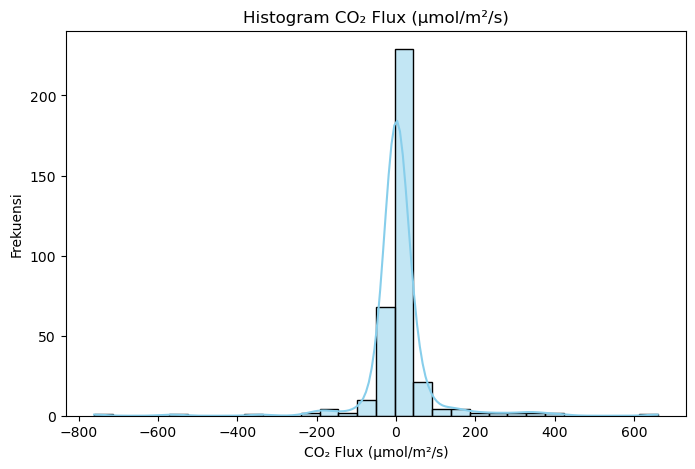

In [23]:
# Menampilkan distribusi data
plt.figure(figsize=(8,5))
sns.histplot(df_30min['C02_flux (μmol/m²/s)'], bins=30, kde=True, color='skyblue')

plt.title('Histogram CO₂ Flux (μmol/m²/s)')
plt.xlabel('CO₂ Flux (μmol/m²/s)')
plt.ylabel('Frekuensi')
plt.show()

In [33]:
# Isi data NaN dengan Interpolasi Time
final_flux = df_30min

final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,Dew point temperature (K),H2O Mole Fraction (mol/mol_a),H2O Mixing Ratio (mol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,296.423658,0.028301,0.018116,-5.888737,-6.059909,0.171172,362.251085,-2.214287,-1.297994,-52.501748
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,297.430246,0.030079,0.019289,-4.973237,-5.793526,0.820289,359.415772,-5.322445,-4.364160,-176.161989
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,298.497538,0.032046,0.020592,-3.915409,-3.915409,0.000000,351.000000,0.000000,0.000000,0.000000
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,298.297514,0.031665,0.020340,-3.507953,-3.398097,-0.109856,351.603082,-0.132013,0.020845,0.840380
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,298.097490,0.031284,0.020087,-3.100497,-2.880785,-0.219712,352.206164,-0.264026,0.041690,1.687392
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,297.537031,0.030248,0.019402,-1.549551,-1.439557,-0.109995,359.621335,1.275161,0.020442,0.828845
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,296.976572,0.029212,0.018717,0.001394,0.001671,-0.000277,367.036506,2.814349,-0.000806,-0.032735
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,297.098827,0.029429,0.018860,0.000253,0.001265,-0.001013,370.821059,7.608350,-0.007936,-0.322394
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,297.128018,0.029463,0.018882,0.002884,0.003079,-0.000196,384.020427,1.203656,-0.000424,-0.017263


- Parameter Fluks $CO_2$ dalam satuan $[\mathrm{ton\ ha^{-1}\ s^{-1} }]$

In [34]:
# Konversi satuan agar menjadi ton/Ha/s
final_flux['ton_hectare_flux'] = final_flux['C02_flux (μmol/m²/s)'] * 44.001 * 1e-8


final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,H2O Mole Fraction (mol/mol_a),H2O Mixing Ratio (mol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s),ton_hectare_flux
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,0.028301,0.018116,-5.888737,-6.059909,0.171172,362.251085,-2.214287,-1.297994,-52.501748,-2.310129e-05
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,0.030079,0.019289,-4.973237,-5.793526,0.820289,359.415772,-5.322445,-4.364160,-176.161989,-7.751304e-05
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,0.032046,0.020592,-3.915409,-3.915409,0.000000,351.000000,0.000000,0.000000,0.000000,0.000000e+00
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,0.031665,0.020340,-3.507953,-3.398097,-0.109856,351.603082,-0.132013,0.020845,0.840380,3.697755e-07
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,0.031284,0.020087,-3.100497,-2.880785,-0.219712,352.206164,-0.264026,0.041690,1.687392,7.424694e-07
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,0.030248,0.019402,-1.549551,-1.439557,-0.109995,359.621335,1.275161,0.020442,0.828845,3.647003e-07
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,0.029212,0.018717,0.001394,0.001671,-0.000277,367.036506,2.814349,-0.000806,-0.032735,-1.440354e-08
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,0.029429,0.018860,0.000253,0.001265,-0.001013,370.821059,7.608350,-0.007936,-0.322394,-1.418566e-07
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,0.029463,0.018882,0.002884,0.003079,-0.000196,384.020427,1.203656,-0.000424,-0.017263,-7.595991e-09


- Parameter Fluks $CO_2$ dalam satuan $[\mathrm{ton\ ha^{-1}\ year^{-1} }]$

In [35]:
# Konversi satuan agar menjadi ton/Ha/year
sec_to_year = 31557600
ton_flux_year = final_flux['ton_hectare_flux'] * sec_to_year
final_flux['ton_flux_year'] = ton_flux_year


final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,H2O Mixing Ratio (mol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s),ton_hectare_flux,ton_flux_year
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,0.018116,-5.888737,-6.059909,0.171172,362.251085,-2.214287,-1.297994,-52.501748,-2.310129e-05,-729.021397
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,0.019289,-4.973237,-5.793526,0.820289,359.415772,-5.322445,-4.364160,-176.161989,-7.751304e-05,-2446.125404
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,0.020592,-3.915409,-3.915409,0.000000,351.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,0.020340,-3.507953,-3.398097,-0.109856,351.603082,-0.132013,0.020845,0.840380,3.697755e-07,11.669227
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,0.020087,-3.100497,-2.880785,-0.219712,352.206164,-0.264026,0.041690,1.687392,7.424694e-07,23.430551
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,0.019402,-1.549551,-1.439557,-0.109995,359.621335,1.275161,0.020442,0.828845,3.647003e-07,11.509065
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,0.018717,0.001394,0.001671,-0.000277,367.036506,2.814349,-0.000806,-0.032735,-1.440354e-08,-0.454541
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,0.018860,0.000253,0.001265,-0.001013,370.821059,7.608350,-0.007936,-0.322394,-1.418566e-07,-4.476653
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,0.018882,0.002884,0.003079,-0.000196,384.020427,1.203656,-0.000424,-0.017263,-7.595991e-09,-0.239711


In [36]:
final_flux.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 358 entries, 2024-06-10 13:00:00 to 2024-06-17 23:30:00
Freq: 30T
Data columns (total 35 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Air Pressure (kPa)                  358 non-null    float64
 1   Air Temperature (Celcius)           358 non-null    float64
 2   Altitude (MSAL)                     358 non-null    float64
 3   Relatif Humidity (%)                358 non-null    float64
 4   Temperature (Celsius)               358 non-null    float64
 5   C02 mole fraction (µmol/mol_a)      358 non-null    float64
 6   CH4 mole fraction (µmol/mol_a)      358 non-null    float64
 7   Water Vapor Mass Density (kg/m^3)   358 non-null    float64
 8   utara (m/s)                         358 non-null    float64
 9   barat (m/s)                         358 non-null    float64
 10  timur (m/s)                         358 non-null    float64
 11

# Visualisasi Data

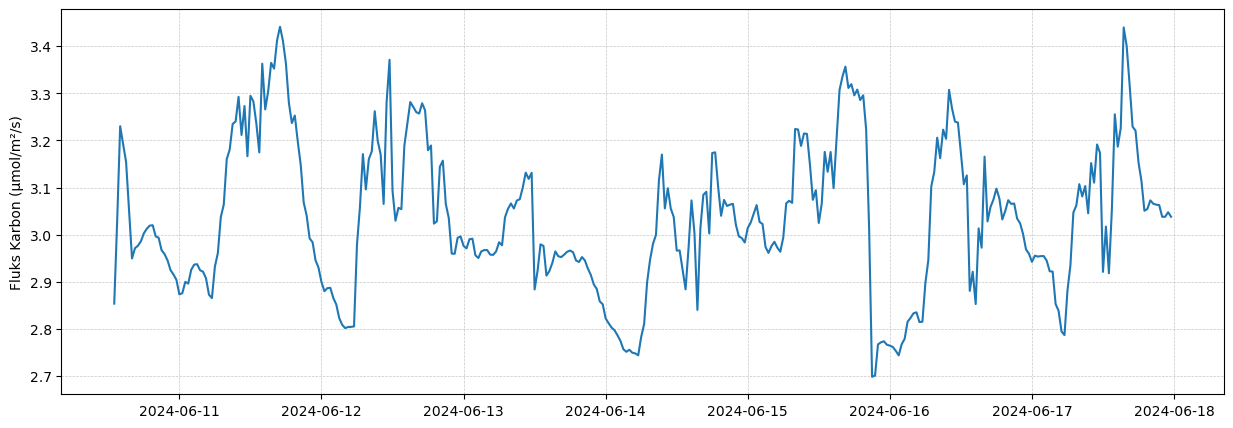

In [43]:
# Menampilkan visualisasi
plt.figure(figsize=(15, 5))
plt.plot(final_flux['Water Vapor Partial Pressure (kPa)'])
plt.ylabel('Fluks Karbon (μmol/m²/s)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.show()

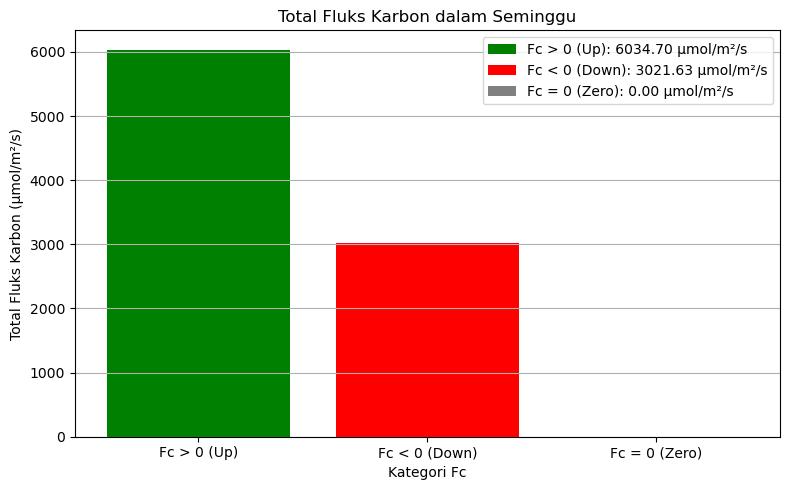

In [27]:
# Ambil kolom Fc
Fc = final_flux['C02_flux (μmol/m²/s)']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].sum()
Fc_neg_sum = -Fc[Fc < 0].sum()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Menyimpan Data

In [28]:
# Simpan data ke csv
final_flux.to_csv('E:/KP RAFI RIDHO RAMADHAN/Hasil/final_data_2.csv')